In [23]:
import numpy as np
import matplotlib.pyplot as plt
import random
import pandas as pd
from scipy import stats 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [24]:
df=pd.read_csv("Simple_House_Price.csv")
dependent_variable = df['Price']
independent_variable = df['Area_sqft']

Text(0.5, 1.0, 'Scatter plot of Area_sqft vs Price')

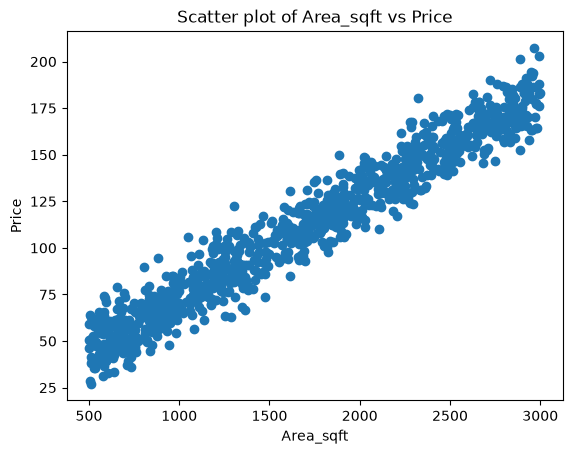

In [25]:
x=independent_variable
y=dependent_variable
plt.scatter(x,y)
plt.xlabel("Area_sqft")
plt.ylabel("Price")
plt.title("Scatter plot of Area_sqft vs Price")

In [26]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=.2,random_state=42)
xtrain = xtrain.values.reshape(-1, 1)
xtest = xtest.values.reshape(-1, 1)
print("Training samples:", len(xtrain))
print("Testing samples:", len(xtest))

print("Training percentage:", (len(xtrain) / len(df)) * 100, "%")
print("Testing percentage:", (len(xtest) / len(df)) * 100, "%")

Training samples: 800
Testing samples: 200
Training percentage: 80.0 %
Testing percentage: 20.0 %


In [29]:
lr=LinearRegression()
lr.fit(xtrain,ytrain)
y_train_pred=lr.predict(xtrain)
print("Predicted values:", y_train_pred)
print("Dimensions of target variable:", ytrain.shape)
print("Dimension of predicted variable:", y_train_pred.shape)

Predicted values: [ 89.2006294   85.9263652   53.83857598  99.62370379 130.29264518
  96.78600814  62.89737362 112.17504991  57.65855089 169.36553137
 149.82908827  69.60961524  68.46362277 141.53428562 140.44286422
 176.2414862  113.97589522  98.96885095 115.06731663  94.16659678
 140.93400385 106.11766113 131.00206909  52.47429923 156.54132989
  55.42113702  72.17445553  86.4720759  127.29123633 169.20181816
 153.37620783 123.19840607 173.89493018 138.53287676 107.91850644
  74.02987192 145.24511839  92.96603324  55.0937106   84.88951487
 157.35989595 122.32526895 167.12811749 105.95394792  71.6833159
  72.33816874  50.18231429 174.00407232 127.29123633 137.93259499
  97.27714778 163.4718558  154.24934495  55.58485023 174.05864339
 116.7590198  174.87720944 178.04233151  49.58203252 144.75397875
  90.89233258 182.40801712  83.25238276 117.68672799 110.48334674
  50.07317215 157.35989595  67.64505672 120.90642112 140.98857492
  72.28359767  63.00651576 129.25579485  81.06953996  49.58

In [34]:
y_test_pred = lr.predict(xtest)
result = pd.DataFrame({
    "Area_sqft": xtest.flatten(),
    "Actual Price": ytest.values,
    "Predicted Price": y_test_pred
})
result["Residual"] = result["Actual Price"] - result["Predicted Price"]

print("\nTesting Results:")
print(result)


Testing Results:
     Area_sqft  Actual Price  Predicted Price   Residual
0         1187         86.90        83.525238   3.374762
1         1991        131.48       127.400378   4.079622
2         2404        159.27       149.938230   9.331770
3         1819        100.71       118.014154 -17.304154
4         1709        118.42       112.011337   6.408663
..         ...           ...              ...        ...
195       1888        139.75       121.779558  17.970442
196       1104         91.04        78.995839  12.044161
197       1353         90.76        92.584036  -1.824036
198       2789        163.61       170.948092  -7.338092
199       1203         72.26        84.398375 -12.138375

[200 rows x 4 columns]


In [37]:
mae = mean_absolute_error(ytest, y_test_pred)
rmse = np.sqrt(mean_squared_error(ytest, y_test_pred))
r2 = r2_score(ytest, y_test_pred)

print("\nModel Evaluation:")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)
if rmse > mae:
    print("\nRMSE is larger than MAE.")
    print("RMSE:", rmse)
    print("MAE:", mae)
else:
    print("\nMAE is larger than RMSE.")
    print("MAE:", mae)
    print("RMSE:", rmse)



Model Evaluation:
MAE: 7.7660138381003385
RMSE: 10.155207775154258
R2 Score: 0.9410312875961606

RMSE is larger than MAE.
RMSE: 10.155207775154258
MAE: 7.7660138381003385
